In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

sns.set_theme(style="whitegrid")

# Load cleaned dataset from GitHub

url = "https://raw.githubusercontent.com/anjaliumesh477/Python-Apprentice-Internship/main/Week-1-Data-Cleaning-EDA/telco_customer_churn_cleaned.csv"

df = pd.read_csv(url)

print("FINAL PROJECT: CUSTOMER CHURN ANALYSIS")
print("--------------------------------------")

print("Dataset Shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

FINAL PROJECT: CUSTOMER CHURN ANALYSIS
--------------------------------------
Dataset Shape: (7043, 21)

First five records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [2]:
# Overall churn analysis

print("CUSTOMER CHURN ANALYSIS")
print("-----------------------")

# Churn rate
churn_rate = df["Churn"].value_counts(normalize=True) * 100

print("\nOverall Churn Rate:")
print(churn_rate.round(2))

# Churn by contract
print("\nChurn Rate by Contract:")
print(
    (pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100)
    .round(2)
)

# Churn by payment method
print("\nChurn Rate by Payment Method:")
print(
    (pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100)
    .round(2)
)

# Average tenure
print("\nAverage Tenure by Churn:")
print(df.groupby("Churn")["tenure"].mean().round(2))

# Average monthly charges
print("\nAverage Monthly Charges by Churn:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

CUSTOMER CHURN ANALYSIS
-----------------------

Overall Churn Rate:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Churn Rate by Contract:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

Churn Rate by Payment Method:
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average Monthly Charges by Churn:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


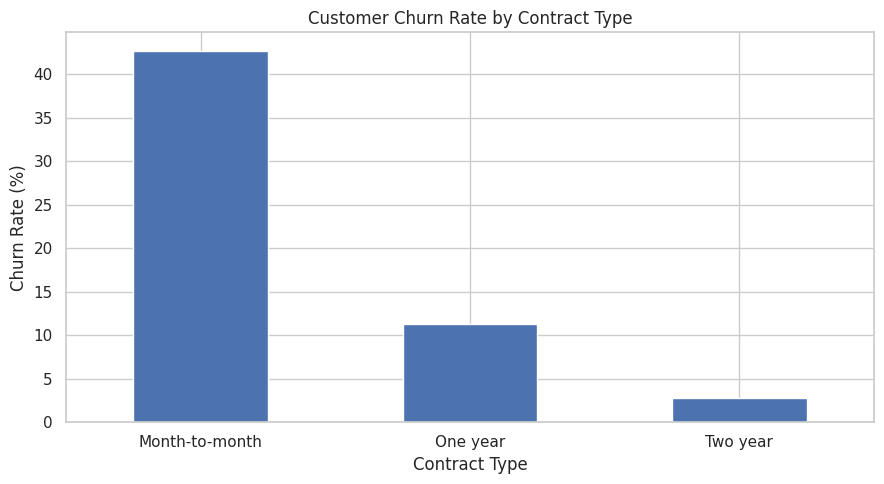

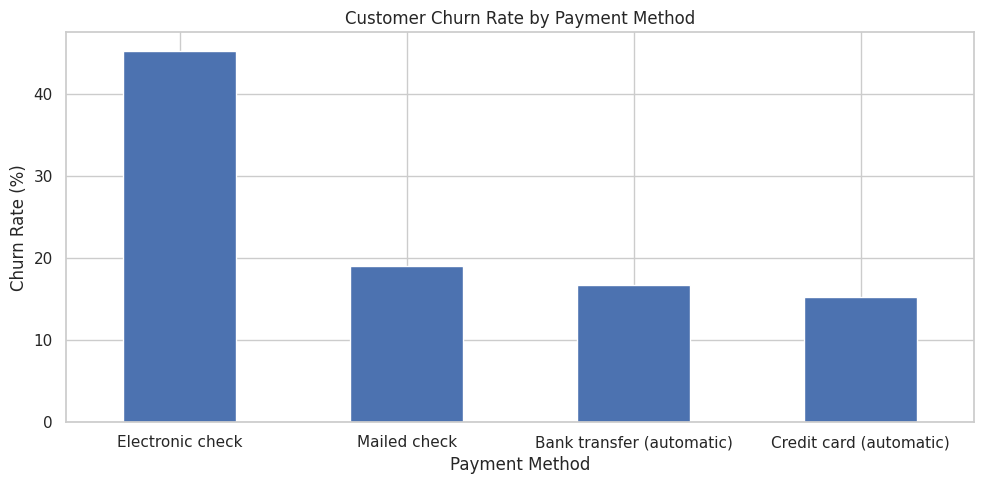

In [5]:
# Calculate churn rates
contract_rate = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
)["Yes"] * 100

payment_rate = pd.crosstab(
    df["PaymentMethod"], df["Churn"], normalize="index"
)["Yes"] * 100

# Visualization 1: Churn by Contract
plt.figure(figsize=(9, 5))
contract_rate.plot(kind="bar")

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualization 2: Churn by Payment Method
plt.figure(figsize=(10, 5))
payment_rate.sort_values(ascending=False).plot(kind="bar")

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Statistical Analysis

# 1. Welch's Independent Samples t-test

stayed = df[df["Churn"] == "No"]["tenure"]
churned = df[df["Churn"] == "Yes"]["tenure"]

t_stat, p_value = stats.ttest_ind(
    stayed,
    churned,
    equal_var=False
)

print("WELCH'S T-TEST")
print("----------------")
print("T-statistic:", round(t_stat, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference in average tenure.")
else:
    print("Conclusion: No significant difference in average tenure.")


# 2. Chi-square Test

contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2, chi_p, dof, expected = chi2_contingency(contract_table)

n = contract_table.to_numpy().sum()
rows, cols = contract_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, cols - 1))
)

print("\nCHI-SQUARE TEST")
print("----------------")
print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", chi_p)
print("Cramer's V:", round(cramers_v, 4))

WELCH'S T-TEST
----------------
T-statistic: 34.8238
P-value: 1.1954945472607151e-232
Conclusion: Significant difference in average tenure.

CHI-SQUARE TEST
----------------
Chi-square statistic: 1184.5966
Degrees of freedom: 2
P-value: 5.863038300673391e-258
Cramer's V: 0.4101


In [7]:
# Prepare data for machine learning

ml_df = df.drop("customerID", axis=1)

X = pd.get_dummies(
    ml_df.drop("Churn", axis=1),
    drop_first=True
)

y = ml_df["Churn"].map({"No": 0, "Yes": 1})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Original Random Forest
original_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

original_model.fit(X_train, y_train)

# Improved Random Forest
improved_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

improved_model.fit(X_train, y_train)

# Evaluate both models
models = {
    "Original Random Forest": original_model,
    "Improved Random Forest": improved_model
}

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n", name)
    print("------------------------------")
    print("Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
    print("Precision:", round(precision_score(y_test, predictions) * 100, 2), "%")
    print("Recall:", round(recall_score(y_test, predictions) * 100, 2), "%")
    print("F1 Score:", round(f1_score(y_test, predictions) * 100, 2), "%")
    print("AUC:", round(roc_auc_score(y_test, probabilities), 4))
    print("Training Accuracy:", round(model.score(X_train, y_train) * 100, 2), "%")
    print("Testing Accuracy:", round(model.score(X_test, y_test) * 100, 2), "%")


 Original Random Forest
------------------------------
Accuracy: 79.13 %
Precision: 63.89 %
Recall: 49.2 %
F1 Score: 55.59 %
AUC: 0.8224
Training Accuracy: 99.8 %
Testing Accuracy: 79.13 %

 Improved Random Forest
------------------------------
Accuracy: 76.3 %
Precision: 53.69 %
Recall: 77.81 %
F1 Score: 63.54 %
AUC: 0.8456
Training Accuracy: 81.75 %
Testing Accuracy: 76.3 %


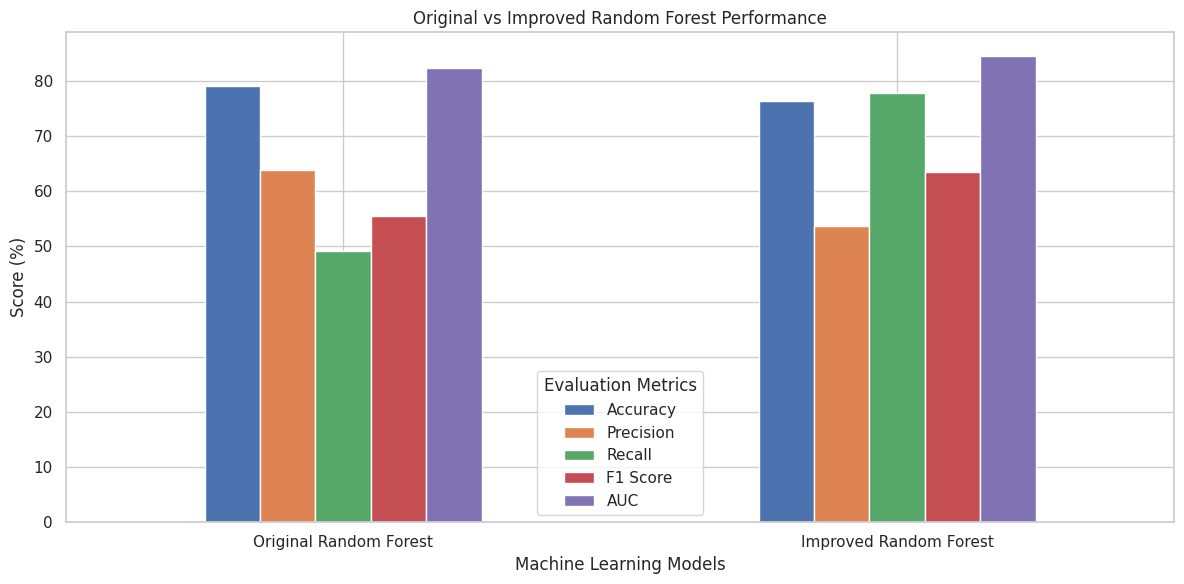

,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,Original Random Forest,79.13,63.89,49.20,55.59,82.24
1,Improved Random Forest,76.30,53.69,77.81,63.54,84.56


In [9]:
# Model performance comparison

comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Improved Random Forest"],
    "Accuracy": [79.13, 76.30],
    "Precision": [63.89, 53.69],
    "Recall": [49.20, 77.81],
    "F1 Score": [55.59, 63.54],
    "AUC": [82.24, 84.56]
})

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Original vs Improved Random Forest Performance")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

display(comparison)